In [2]:
import os
print(os.getcwd())


C:\Users\pilaa\anaconda_projects\30a63e16-11cd-48bf-9764-7519d6a48f79


In [3]:
import os
print(os.getcwd())



C:\Users\pilaa\anaconda_projects\30a63e16-11cd-48bf-9764-7519d6a48f79


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
df = pd.read_csv('heart.csv')

print("DATASET OVERVIEW")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns\n")
print(df.head())
print("\n--- Data Types ---")
print(df.dtypes)
print("\n--- Basic Statistics ---")
print(df.describe())
print("\n--- Missing Values ---")
print(df.isnull().sum())
print("\n--- Target Distribution ---")
print(df['HeartDisease'].value_counts())
print(f"\n  0 = No Heart Disease: {(df['HeartDisease']==0).sum()} patients")
print(f"  1 = Heart Disease:    {(df['HeartDisease']==1).sum()} patients")

DATASET OVERVIEW
Shape: 918 rows x 12 columns

   Age Sex ChestPainType  RestingBP  Cholesterol  FastingBS RestingECG  MaxHR  \
0   40   M           ATA        140          289          0     Normal    172   
1   49   F           NAP        160          180          0     Normal    156   
2   37   M           ATA        130          283          0         ST     98   
3   48   F           ASY        138          214          0     Normal    108   
4   54   M           NAP        150          195          0     Normal    122   

  ExerciseAngina  Oldpeak ST_Slope  HeartDisease  
0              N      0.0       Up             0  
1              N      1.0     Flat             1  
2              N      0.0       Up             0  
3              Y      1.5     Flat             1  
4              N      0.0       Up             0  

--- Data Types ---
Age                 int64
Sex                object
ChestPainType      object
RestingBP           int64
Cholesterol         int64
FastingBS 

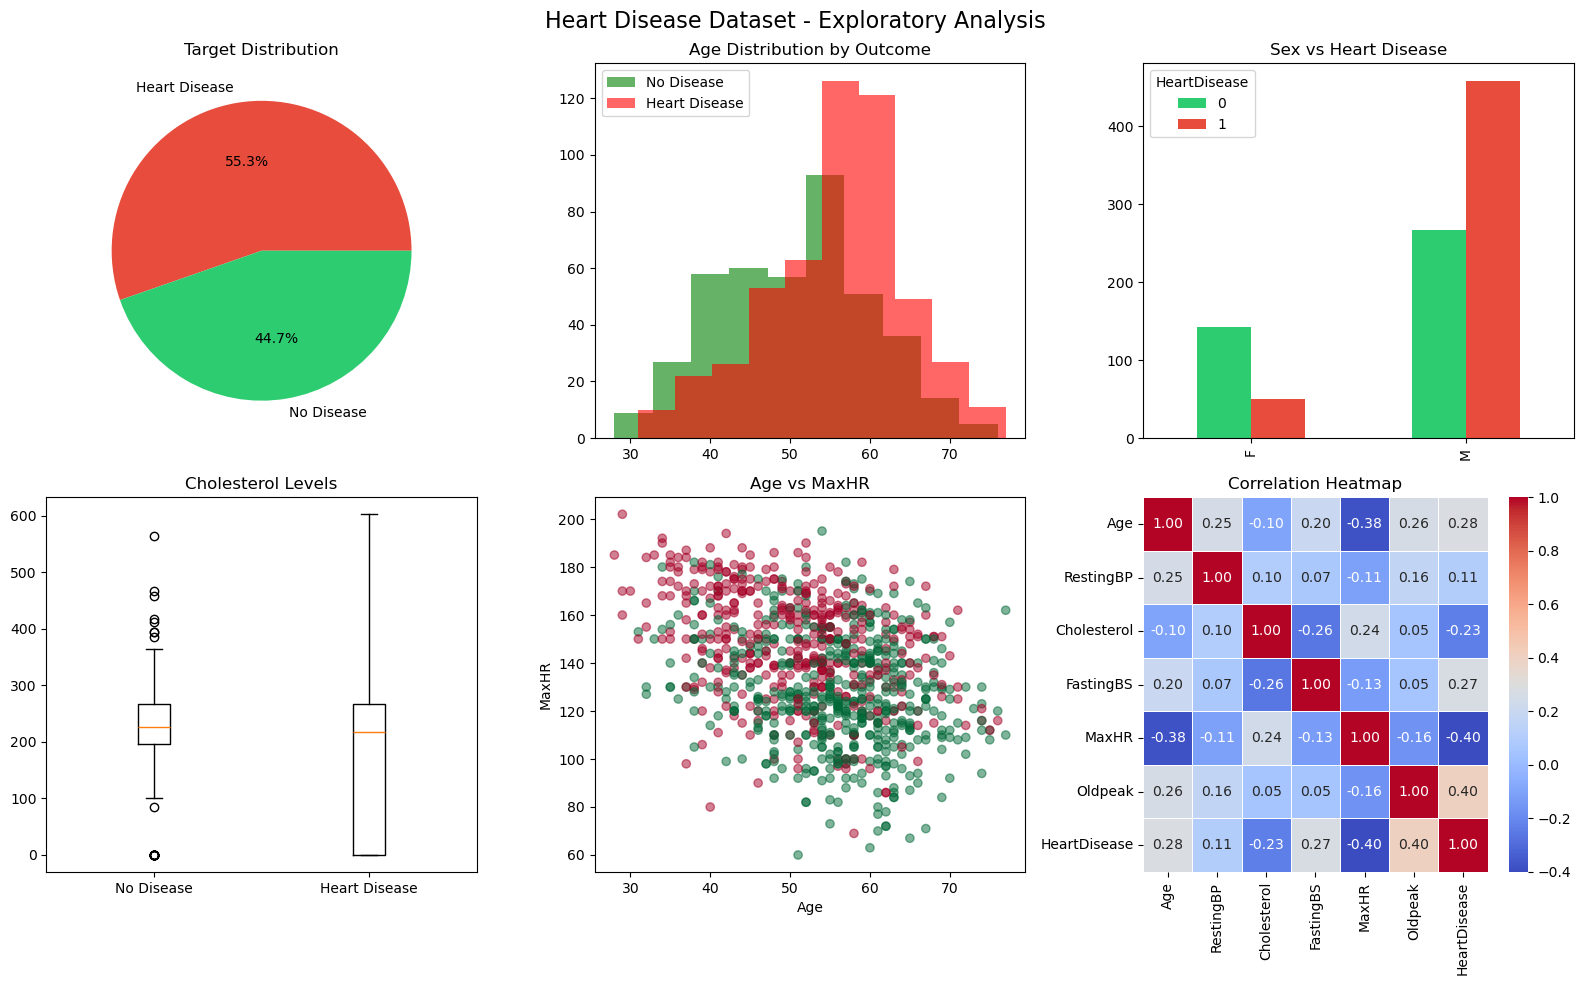

EDA plots saved.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle("Heart Disease Dataset - Exploratory Analysis", fontsize=16)

axes[0,0].pie(df['HeartDisease'].value_counts(), labels=['Heart Disease','No Disease'],
              autopct='%1.1f%%', colors=['#e74c3c','#2ecc71'])
axes[0,0].set_title("Target Distribution")

axes[0,1].hist(df[df['HeartDisease']==0]['Age'], alpha=0.6, label='No Disease', color='green')
axes[0,1].hist(df[df['HeartDisease']==1]['Age'], alpha=0.6, label='Heart Disease', color='red')
axes[0,1].set_title("Age Distribution by Outcome")
axes[0,1].legend()

sex_counts = df.groupby(['Sex','HeartDisease']).size().unstack()
sex_counts.plot(kind='bar', ax=axes[0,2], color=['#2ecc71','#e74c3c'])
axes[0,2].set_title("Sex vs Heart Disease")
axes[0,2].set_xlabel("")

axes[1,0].boxplot([df[df['HeartDisease']==0]['Cholesterol'],
                    df[df['HeartDisease']==1]['Cholesterol']],
                   labels=['No Disease','Heart Disease'])
axes[1,0].set_title("Cholesterol Levels")

axes[1,1].scatter(df['Age'], df['MaxHR'], c=df['HeartDisease'],
                   cmap='RdYlGn', alpha=0.5)
axes[1,1].set_title("Age vs MaxHR")
axes[1,1].set_xlabel("Age")
axes[1,1].set_ylabel("MaxHR")

num_df = df.select_dtypes(include='number')
sns.heatmap(num_df.corr(), ax=axes[1,2], annot=True, fmt=".2f",
            cmap='coolwarm', linewidths=0.5)
axes[1,2].set_title("Correlation Heatmap")

plt.tight_layout()
os.makedirs('figures', exist_ok=True)
plt.savefig('figures/eda_plots.png', dpi=150, bbox_inches='tight')
plt.show()
print("EDA plots saved.")

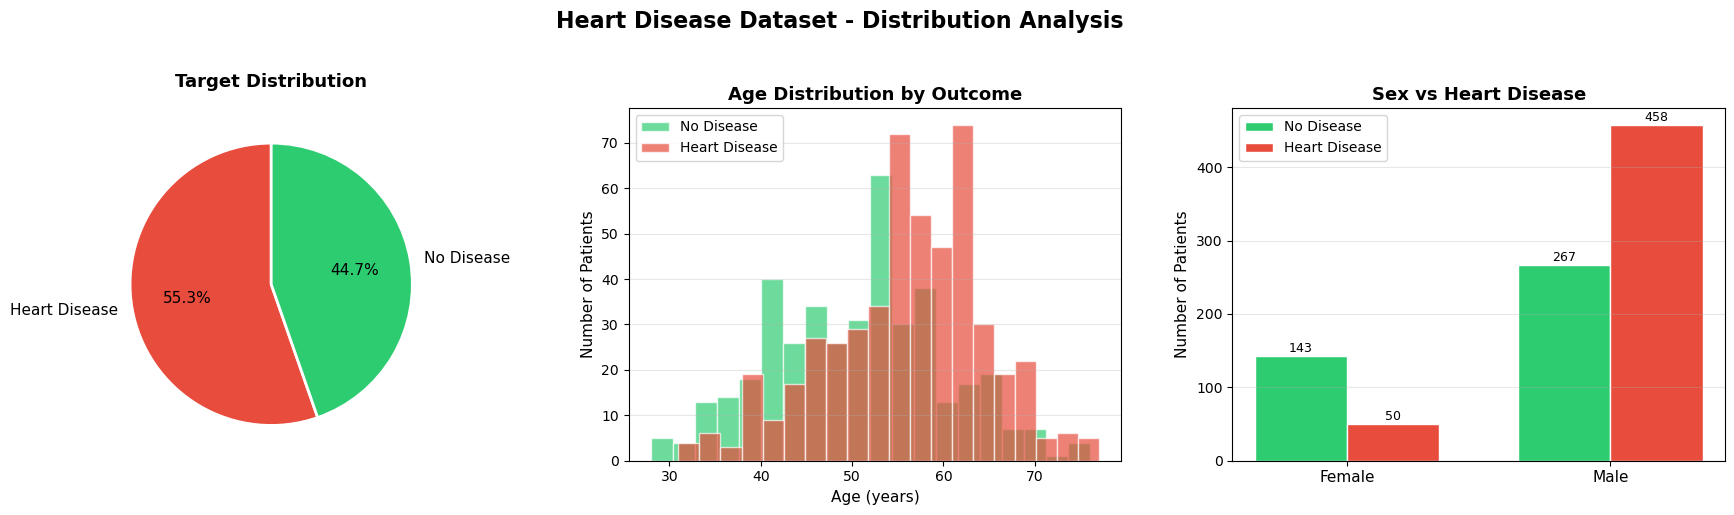

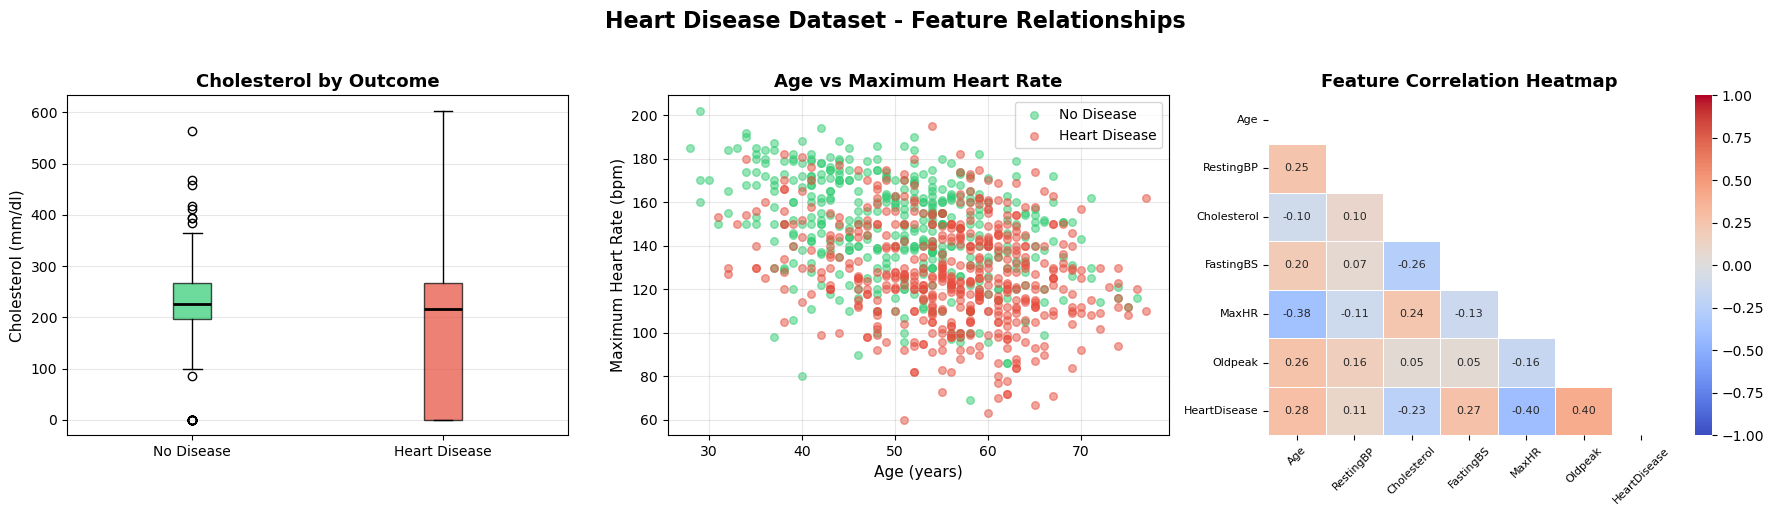

EDA plots saved: eda_distributions.png and eda_relationships.png


In [ ]:
# -----------------------------------------------
# FIGURE 1: Distribution Plots
# -----------------------------------------------
fig1, axes1 = plt.subplots(1, 3, figsize=(18, 5))
fig1.suptitle("Heart Disease Dataset - Distribution Analysis", fontsize=16, fontweight='bold', y=1.02)

# --- Plot 1: Target Distribution (Pie) ---
target_counts = df['HeartDisease'].value_counts()
wedge_props = {'edgecolor': 'white', 'linewidth': 2}
axes1[0].pie(
    target_counts,
    labels=['Heart Disease', 'No Disease'],
    autopct='%1.1f%%',
    colors=['#e74c3c', '#2ecc71'],
    wedgeprops=wedge_props,
    startangle=90,
    textprops={'fontsize': 11}
)
axes1[0].set_title("Target Distribution", fontsize=13, fontweight='bold', pad=15)

# --- Plot 2: Age Distribution by Outcome ---
axes1[1].hist(df[df['HeartDisease']==0]['Age'], bins=20, alpha=0.7,
              label='No Disease', color='#2ecc71', edgecolor='white')
axes1[1].hist(df[df['HeartDisease']==1]['Age'], bins=20, alpha=0.7,
              label='Heart Disease', color='#e74c3c', edgecolor='white')
axes1[1].set_title("Age Distribution by Outcome", fontsize=13, fontweight='bold')
axes1[1].set_xlabel("Age (years)", fontsize=11)
axes1[1].set_ylabel("Number of Patients", fontsize=11)
axes1[1].legend(fontsize=10)
axes1[1].grid(axis='y', alpha=0.3)

# --- Plot 3: Sex vs Heart Disease (Grouped Bar) ---
sex_counts = df.groupby(['Sex', 'HeartDisease']).size().unstack()
sex_counts.columns = ['No Disease', 'Heart Disease']
x = range(len(sex_counts))
width = 0.35
axes1[2].bar([i - width/2 for i in x], sex_counts['No Disease'],
             width=width, label='No Disease', color='#2ecc71', edgecolor='white')
axes1[2].bar([i + width/2 for i in x], sex_counts['Heart Disease'],
             width=width, label='Heart Disease', color='#e74c3c', edgecolor='white')
axes1[2].set_xticks(list(x))
axes1[2].set_xticklabels(['Female', 'Male'], fontsize=11)
axes1[2].set_title("Sex vs Heart Disease", fontsize=13, fontweight='bold')
axes1[2].set_ylabel("Number of Patients", fontsize=11)
axes1[2].legend(fontsize=10)
axes1[2].grid(axis='y', alpha=0.3)
for i, (nd, hd) in enumerate(zip(sex_counts['No Disease'], sex_counts['Heart Disease'])):
    axes1[2].text(i - width/2, nd + 1, str(nd), ha='center', va='bottom', fontsize=9)
    axes1[2].text(i + width/2, hd + 1, str(hd), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.savefig('figures/eda_distributions.png', dpi=150, bbox_inches='tight')
plt.show()


# -----------------------------------------------
# FIGURE 2: Feature Relationship Plots
# -----------------------------------------------
fig2, axes2 = plt.subplots(1, 3, figsize=(18, 5))
fig2.suptitle("Heart Disease Dataset - Feature Relationships", fontsize=16, fontweight='bold', y=1.02)

# --- Plot 4: Cholesterol Boxplot ---
bp = axes2[0].boxplot(
    [df[df['HeartDisease']==0]['Cholesterol'],
     df[df['HeartDisease']==1]['Cholesterol']],
    labels=['No Disease', 'Heart Disease'],
    patch_artist=True,
    medianprops={'color': 'black', 'linewidth': 2}
)
bp['boxes'][0].set_facecolor('#2ecc71')
bp['boxes'][1].set_facecolor('#e74c3c')
for box in bp['boxes']:
    box.set_alpha(0.7)
axes2[0].set_title("Cholesterol by Outcome", fontsize=13, fontweight='bold')
axes2[0].set_ylabel("Cholesterol (mm/dl)", fontsize=11)
axes2[0].grid(axis='y', alpha=0.3)

# --- Plot 5: Age vs MaxHR Scatter ---
no_disease = df[df['HeartDisease'] == 0]
has_disease = df[df['HeartDisease'] == 1]
axes2[1].scatter(no_disease['Age'], no_disease['MaxHR'],
                  color='#2ecc71', alpha=0.5, s=30, label='No Disease')
axes2[1].scatter(has_disease['Age'], has_disease['MaxHR'],
                  color='#e74c3c', alpha=0.5, s=30, label='Heart Disease')
axes2[1].set_title("Age vs Maximum Heart Rate", fontsize=13, fontweight='bold')
axes2[1].set_xlabel("Age (years)", fontsize=11)
axes2[1].set_ylabel("Maximum Heart Rate (bpm)", fontsize=11)
axes2[1].legend(fontsize=10)
axes2[1].grid(alpha=0.3)

# --- Plot 6: Correlation Heatmap ---
num_df = df.select_dtypes(include='number')
corr = num_df.corr()
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True  # show only lower triangle
sns.heatmap(
    corr,
    ax=axes2[2],
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 8},
    vmin=-1, vmax=1,
    mask=mask
)
axes2[2].set_title("Feature Correlation Heatmap", fontsize=13, fontweight='bold')
axes2[2].tick_params(axis='x', rotation=45, labelsize=8)
axes2[2].tick_params(axis='y', rotation=0, labelsize=8)

plt.tight_layout()
plt.savefig('figures/eda_relationships.png', dpi=150, bbox_inches='tight')
plt.show()

print("EDA plots saved: eda_distributions.png and eda_relationships.png")

In [8]:
df_proc = df.copy()

le = LabelEncoder()
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

print("Label Encoding:")
for col in cat_cols:
    df_proc[col] = le.fit_transform(df_proc[col])
    print(f"  {col}: {df[col].unique()} -> {df_proc[col].unique()}")

print(f"\nZero Cholesterol entries: {(df_proc['Cholesterol'] == 0).sum()}")
df_proc['Cholesterol'] = df_proc['Cholesterol'].replace(0, df_proc['Cholesterol'].median())
print("  Replaced with median:", df_proc['Cholesterol'].median())

X = df_proc.drop('HeartDisease', axis=1)
y = df_proc['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"\nPreprocessing complete!")
print(f"   Training samples: {X_train.shape[0]}")
print(f"   Testing samples:  {X_test.shape[0]}")
print(f"   Features: {X.shape[1]}")

Label Encoding:
  Sex: ['M' 'F'] -> [1 0]
  ChestPainType: ['ATA' 'NAP' 'ASY' 'TA'] -> [1 2 0 3]
  RestingECG: ['Normal' 'ST' 'LVH'] -> [1 2 0]
  ExerciseAngina: ['N' 'Y'] -> [0 1]
  ST_Slope: ['Up' 'Flat' 'Down'] -> [2 1 0]

Zero Cholesterol entries: 172
  Replaced with median: 223.0

Preprocessing complete!
   Training samples: 734
   Testing samples:  184
   Features: 11


In [9]:
results = {}

start = time.time()
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
lr_time = time.time() - start
lr_pred = lr.predict(X_test_scaled)
results['Logistic Regression'] = {
    'model': lr, 'pred': lr_pred,
    'accuracy': accuracy_score(y_test, lr_pred),
    'time': lr_time
}
print(f"Logistic Regression -- Accuracy: {results['Logistic Regression']['accuracy']:.4f} | Time: {lr_time:.4f}s")

start = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_time = time.time() - start
rf_pred = rf.predict(X_test)
results['Random Forest'] = {
    'model': rf, 'pred': rf_pred,
    'accuracy': accuracy_score(y_test, rf_pred),
    'time': rf_time
}
print(f"Random Forest     -- Accuracy: {results['Random Forest']['accuracy']:.4f} | Time: {rf_time:.4f}s")

start = time.time()
svm = SVC(kernel='rbf', probability=True, random_state=42)
svm.fit(X_train_scaled, y_train)
svm_time = time.time() - start
svm_pred = svm.predict(X_test_scaled)
results['SVM'] = {
    'model': svm, 'pred': svm_pred,
    'accuracy': accuracy_score(y_test, svm_pred),
    'time': svm_time
}
print(f"SVM               -- Accuracy: {results['SVM']['accuracy']:.4f} | Time: {svm_time:.4f}s")

Logistic Regression -- Accuracy: 0.8478 | Time: 0.1969s
Random Forest     -- Accuracy: 0.8750 | Time: 0.8949s
SVM               -- Accuracy: 0.8587 | Time: 0.4385s



MATHEMATICS: LOGISTIC REGRESSION

1. Linear combination of inputs:
      z = B0 + B1*x1 + B2*x2 + ... + Bn*xn

2. Sigmoid activation to squash output to [0,1]:
      sigmoid(z) = 1 / (1 + e^(-z))

3. Predicted probability:
      P(y=1|x) = sigmoid(z)
      Decision: y_hat = 1 if P > 0.5, else 0

4. Loss Function (Binary Cross-Entropy):
      L = -1/N * sum[ yi*log(y_hat_i) + (1-yi)*log(1-y_hat_i) ]

5. Optimization (Gradient Descent):
      Bj = Bj - alpha * dL/dBj
      where alpha = learning rate

Learned Coefficients (feature importance):
       Feature  Coefficient
           Sex     0.560862
     FastingBS     0.532247
ExerciseAngina     0.496518
       Oldpeak     0.226366
           Age     0.070739
   Cholesterol     0.035648
     RestingBP     0.012630
    RestingECG    -0.092305
         MaxHR    -0.356359
 ChestPainType    -0.676644
      ST_Slope    -1.189409


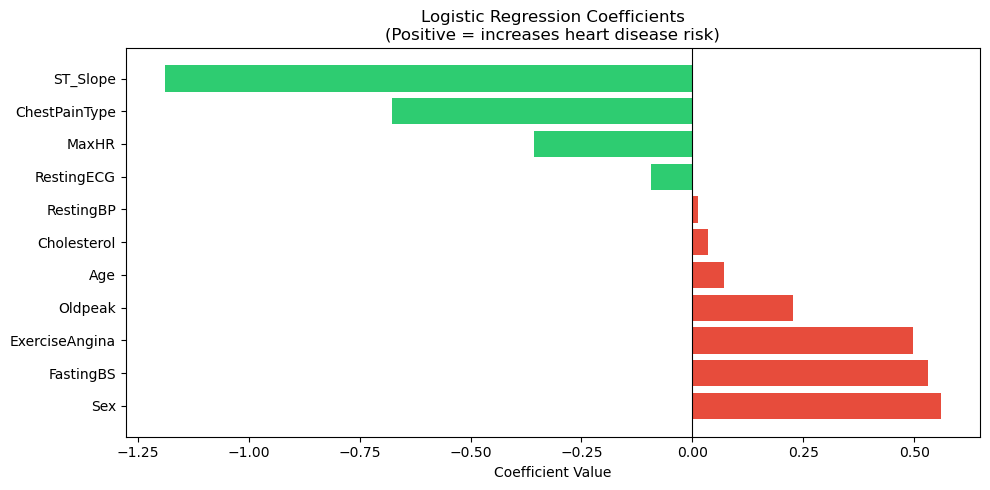

In [ ]:
print("""
MATHEMATICS: LOGISTIC REGRESSION
==================================

1. Linear combination of inputs:
      z = B0 + B1*x1 + B2*x2 + ... + Bn*xn

2. Sigmoid activation to squash output to [0,1]:
      sigmoid(z) = 1 / (1 + e^(-z))

3. Predicted probability:
      P(y=1|x) = sigmoid(z)
      Decision: y_hat = 1 if P > 0.5, else 0

4. Loss Function (Binary Cross-Entropy):
      L = -1/N * sum[ yi*log(y_hat_i) + (1-yi)*log(1-y_hat_i) ]

5. Optimization (Gradient Descent):
      Bj = Bj - alpha * dL/dBj
      where alpha = learning rate
""")

coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_[0]
}).sort_values('Coefficient', ascending=False)

print("Learned Coefficients (feature importance):")
print(coef_df.to_string(index=False))

plt.figure(figsize=(10,5))
colors = ['#e74c3c' if c > 0 else '#2ecc71' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.axvline(0, color='black', linewidth=0.8)
plt.title("Logistic Regression Coefficients\n(Positive = increases heart disease risk)")
plt.xlabel("Coefficient Value")
plt.tight_layout()
plt.savefig('figures/lr_coefficients.png', dpi=150)
plt.show()

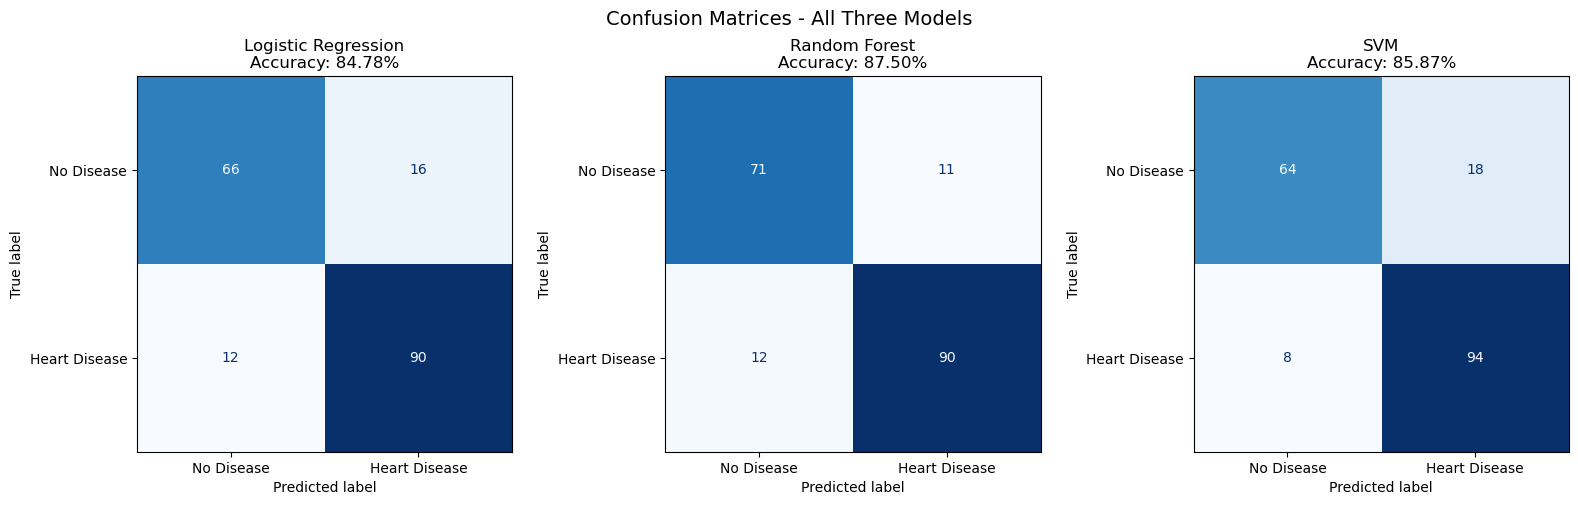


Logistic Regression -- Classification Report
               precision    recall  f1-score   support

   No Disease       0.85      0.80      0.82        82
Heart Disease       0.85      0.88      0.87       102

     accuracy                           0.85       184
    macro avg       0.85      0.84      0.85       184
 weighted avg       0.85      0.85      0.85       184


Random Forest -- Classification Report
               precision    recall  f1-score   support

   No Disease       0.86      0.87      0.86        82
Heart Disease       0.89      0.88      0.89       102

     accuracy                           0.88       184
    macro avg       0.87      0.87      0.87       184
 weighted avg       0.88      0.88      0.88       184


SVM -- Classification Report
               precision    recall  f1-score   support

   No Disease       0.89      0.78      0.83        82
Heart Disease       0.84      0.92      0.88       102

     accuracy                           0.86       

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Confusion Matrices - All Three Models", fontsize=14)

for ax, (name, res) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, res['pred'])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                   display_labels=['No Disease','Heart Disease'])
    disp.plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f"{name}\nAccuracy: {res['accuracy']:.2%}")

plt.tight_layout()
plt.savefig('figures/confusion_matrices.png', dpi=150)
plt.show()

for name, res in results.items():
    print(f"\n{'='*50}")
    print(f"{name} -- Classification Report")
    print('='*50)
    print(classification_report(y_test, res['pred'],
                                  target_names=['No Disease','Heart Disease']))

ALGORITHM 1: LINEAR REGRESSION
Task: Prediction (predicting Maximum Heart Rate)
  Mean Squared Error  (MSE) : 484.7439
  Root Mean Sq Error (RMSE) : 22.0169
  Mean Absolute Error (MAE) : 17.3099
  R-squared           (R2)  : 0.2731
  Training Time             : 0.1868s


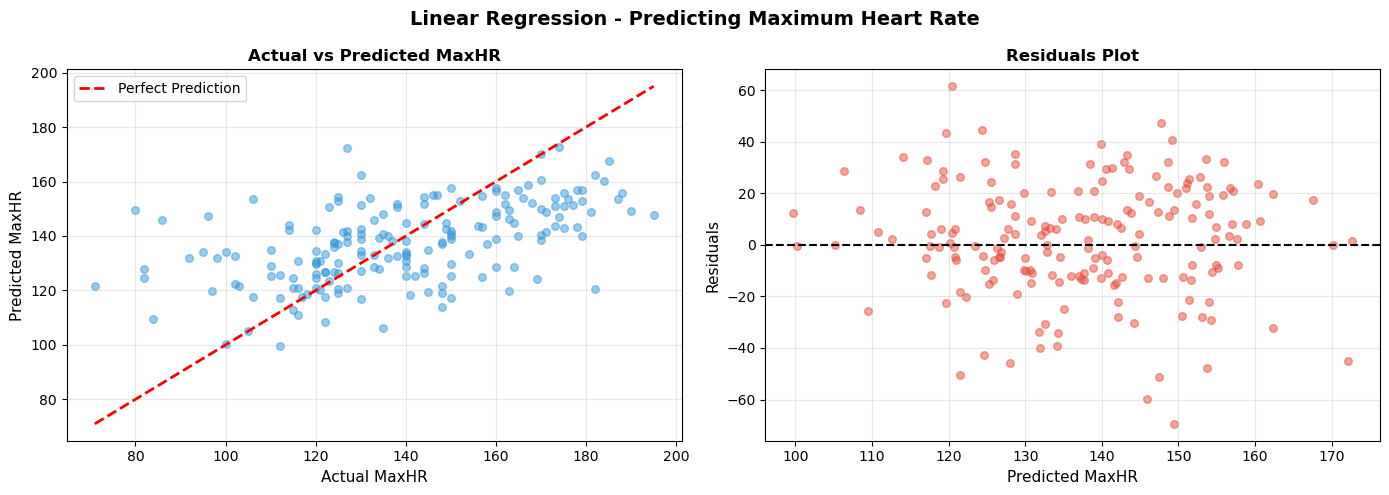


Feature Coefficients:
       Feature  Coefficient
      ST_Slope     5.379976
 ChestPainType     4.223863
       Oldpeak     3.306908
   Cholesterol     0.768606
     FastingBS     0.208034
     RestingBP    -0.285312
           Sex    -2.386063
    RestingECG    -3.594088
ExerciseAngina    -4.522243
           Age    -7.616762

Linear Regression complete.


In [ ]:
# =============================================
# CELL 5A: ALGORITHM 1 - LINEAR REGRESSION (PREDICTION)
# Task: Predict MaxHR (Maximum Heart Rate) from other features
# =============================================
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# For regression we predict MaxHR instead of HeartDisease
X_reg = df_proc.drop(['HeartDisease', 'MaxHR'], axis=1)
y_reg = df_proc['MaxHR']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42)

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled  = scaler_reg.transform(X_test_reg)

# Train
start = time.time()
lr_reg = LinearRegression()
lr_reg.fit(X_train_reg_scaled, y_train_reg)
lr_reg_time = time.time() - start

# Predict
y_pred_reg = lr_reg.predict(X_test_reg_scaled)

# Metrics
mse  = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
mae  = mean_absolute_error(y_test_reg, y_pred_reg)
r2   = r2_score(y_test_reg, y_pred_reg)

print("ALGORITHM 1: LINEAR REGRESSION")
print("Task: Prediction (predicting Maximum Heart Rate)")
print("="*50)
print(f"  Mean Squared Error  (MSE) : {mse:.4f}")
print(f"  Root Mean Sq Error (RMSE) : {rmse:.4f}")
print(f"  Mean Absolute Error (MAE) : {mae:.4f}")
print(f"  R-squared           (R2)  : {r2:.4f}")
print(f"  Training Time             : {lr_reg_time:.4f}s")

# Visualise actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Linear Regression - Predicting Maximum Heart Rate", fontsize=14, fontweight='bold')

# Actual vs Predicted scatter
axes[0].scatter(y_test_reg, y_pred_reg, color='#3498db', alpha=0.5, s=30)
axes[0].plot([y_test_reg.min(), y_test_reg.max()],
             [y_test_reg.min(), y_test_reg.max()],
             'r--', linewidth=2, label='Perfect Prediction')
axes[0].set_xlabel("Actual MaxHR", fontsize=11)
axes[0].set_ylabel("Predicted MaxHR", fontsize=11)
axes[0].set_title("Actual vs Predicted MaxHR", fontsize=12, fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Residuals plot
residuals = y_test_reg - y_pred_reg
axes[1].scatter(y_pred_reg, residuals, color='#e74c3c', alpha=0.5, s=30)
axes[1].axhline(0, color='black', linewidth=1.5, linestyle='--')
axes[1].set_xlabel("Predicted MaxHR", fontsize=11)
axes[1].set_ylabel("Residuals", fontsize=11)
axes[1].set_title("Residuals Plot", fontsize=12, fontweight='bold')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figures/linear_regression.png', dpi=150, bbox_inches='tight')
plt.show()

# Feature importance via coefficients
coef_reg_df = pd.DataFrame({
    'Feature': X_reg.columns,
    'Coefficient': lr_reg.coef_
}).sort_values('Coefficient', ascending=False)

print("\nFeature Coefficients:")
print(coef_reg_df.to_string(index=False))

# Store result for comparison later
results_all = {}
results_all['Linear Regression (Prediction)'] = {
    'type': 'Prediction',
    'metric': f"R2 = {r2:.4f}",
    'time': lr_reg_time
}
print("\nLinear Regression complete.")

ALGORITHM 2: RANDOM FOREST CLASSIFIER
Task: Classification (Heart Disease: Yes or No)
  Accuracy      : 0.8750 (87.50%)
  Training Time : 1.6290s

Classification Report:
               precision    recall  f1-score   support

   No Disease       0.86      0.87      0.86        82
Heart Disease       0.89      0.88      0.89       102

     accuracy                           0.88       184
    macro avg       0.87      0.87      0.87       184
 weighted avg       0.88      0.88      0.88       184



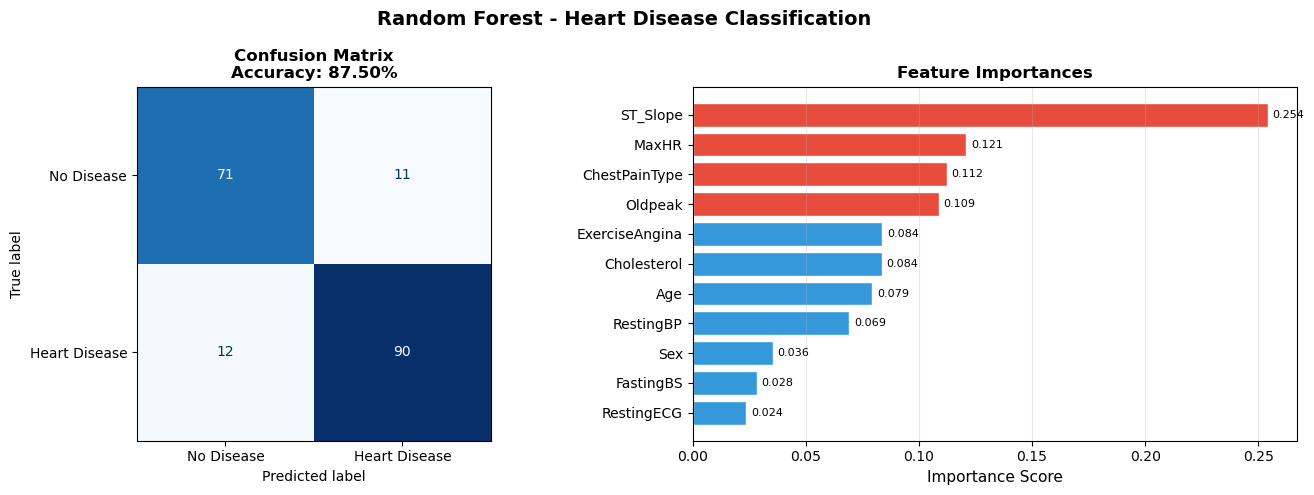

Random Forest complete.


In [ ]:
# =============================================
# CELL 5B: ALGORITHM 2 - RANDOM FOREST (CLASSIFICATION)
# Task: Classify whether a patient has heart disease (0 or 1)
# =============================================
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

# Train
start = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
rf_time = time.time() - start

# Predict
rf_pred = rf.predict(X_test)
rf_acc  = accuracy_score(y_test, rf_pred)

print("ALGORITHM 2: RANDOM FOREST CLASSIFIER")
print("Task: Classification (Heart Disease: Yes or No)")
print("="*50)
print(f"  Accuracy      : {rf_acc:.4f} ({rf_acc*100:.2f}%)")
print(f"  Training Time : {rf_time:.4f}s")
print("\nClassification Report:")
print(classification_report(y_test, rf_pred,
                             target_names=['No Disease', 'Heart Disease']))

# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Random Forest - Heart Disease Classification", fontsize=14, fontweight='bold')

cm = confusion_matrix(y_test, rf_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=['No Disease', 'Heart Disease'])
disp.plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f"Confusion Matrix\nAccuracy: {rf_acc:.2%}", fontsize=12, fontweight='bold')

# Feature Importance
feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=True)

colors = ['#e74c3c' if i >= feat_imp['Importance'].quantile(0.7)
          else '#3498db' for i in feat_imp['Importance']]
axes[1].barh(feat_imp['Feature'], feat_imp['Importance'],
             color=colors, edgecolor='white')
axes[1].set_title("Feature Importances", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Importance Score", fontsize=11)
axes[1].grid(axis='x', alpha=0.3)
for i, v in enumerate(feat_imp['Importance']):
    axes[1].text(v + 0.002, i, f"{v:.3f}", va='center', fontsize=8)

plt.tight_layout()
plt.savefig('figures/random_forest.png', dpi=150, bbox_inches='tight')
plt.show()

results_all['Random Forest (Classification)'] = {
    'type': 'Classification',
    'metric': f"Accuracy = {rf_acc:.4f}",
    'time': rf_time
}
print("Random Forest complete.")

  File "C:\Users\pilaa\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 247, in _count_physical_cores
    cpu_count_physical = _count_physical_cores_win32()
  File "C:\Users\pilaa\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 299, in _count_physical_cores_win32
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\pilaa\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\pilaa\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                     

ALGORITHM 3: KMEANS CLUSTERING
Task: Clustering (Grouping patients by clinical similarity)
  Number of Clusters  : 2
  Silhouette Score    : 0.1806  (closer to 1.0 = better separation)
  Training Time       : 0.1150s
  Cluster 0 size      : 350 patients
  Cluster 1 size      : 384 patients


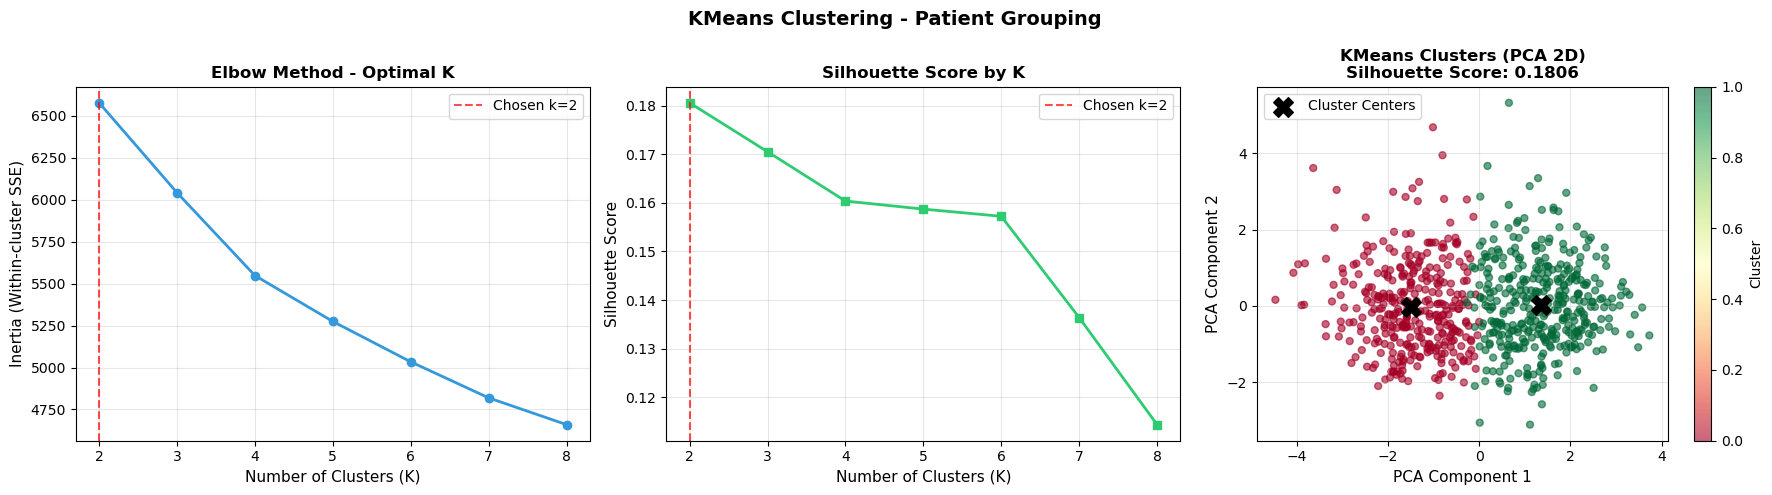

KMeans Clustering complete.


In [ ]:
# =============================================
# CELL 5C: ALGORITHM 3 - KMEANS (CLUSTERING)
# Task: Group patients into clusters based on clinical features
# =============================================
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# --- Find optimal number of clusters using Elbow Method ---
inertias = []
silhouette_scores = []
k_range = range(2, 9)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_train_scaled)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_train_scaled, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("KMeans Clustering - Patient Grouping", fontsize=14, fontweight='bold')

# Elbow curve
axes[0].plot(list(k_range), inertias, 'o-', color='#3498db', linewidth=2, markersize=6)
axes[0].axvline(x=2, color='red', linestyle='--', alpha=0.7, label='Chosen k=2')
axes[0].set_title("Elbow Method - Optimal K", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Number of Clusters (K)", fontsize=11)
axes[0].set_ylabel("Inertia (Within-cluster SSE)", fontsize=11)
axes[0].legend()
axes[0].grid(alpha=0.3)

# Silhouette scores
axes[1].plot(list(k_range), silhouette_scores, 's-', color='#2ecc71', linewidth=2, markersize=6)
axes[1].axvline(x=2, color='red', linestyle='--', alpha=0.7, label='Chosen k=2')
axes[1].set_title("Silhouette Score by K", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Number of Clusters (K)", fontsize=11)
axes[1].set_ylabel("Silhouette Score", fontsize=11)
axes[1].legend()
axes[1].grid(alpha=0.3)

# Train final KMeans with k=2
start = time.time()
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_train_scaled)
kmeans_time = time.time() - start

sil_score = silhouette_score(X_train_scaled, cluster_labels)

print("ALGORITHM 3: KMEANS CLUSTERING")
print("Task: Clustering (Grouping patients by clinical similarity)")
print("="*50)
print(f"  Number of Clusters  : 2")
print(f"  Silhouette Score    : {sil_score:.4f}  (closer to 1.0 = better separation)")
print(f"  Training Time       : {kmeans_time:.4f}s")
print(f"  Cluster 0 size      : {(cluster_labels == 0).sum()} patients")
print(f"  Cluster 1 size      : {(cluster_labels == 1).sum()} patients")

# PCA for 2D visualisation
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

scatter = axes[2].scatter(X_pca[:,0], X_pca[:,1],
                           c=cluster_labels, cmap='RdYlGn',
                           alpha=0.6, s=25)
centers_pca = pca.transform(kmeans.cluster_centers_)
axes[2].scatter(centers_pca[:,0], centers_pca[:,1],
                c='black', marker='X', s=200,
                label='Cluster Centers', zorder=5)
axes[2].set_title(f"KMeans Clusters (PCA 2D)\nSilhouette Score: {sil_score:.4f}",
                   fontsize=12, fontweight='bold')
axes[2].set_xlabel("PCA Component 1", fontsize=11)
axes[2].set_ylabel("PCA Component 2", fontsize=11)
axes[2].legend(fontsize=10)
axes[2].grid(alpha=0.3)
plt.colorbar(scatter, ax=axes[2], label='Cluster')

plt.tight_layout()
plt.savefig('figures/kmeans_clustering.png', dpi=150, bbox_inches='tight')
plt.show()

results_all['KMeans (Clustering)'] = {
    'type': 'Clustering',
    'metric': f"Silhouette = {sil_score:.4f}",
    'time': kmeans_time
}
print("KMeans Clustering complete.")

COMPARATIVE SUMMARY OF ALL THREE ALGORITHMS
Algorithm                           Task            Metric                    Time (s)
------------------------------------------------------------
Linear Regression (Prediction)      Prediction      R2 = 0.2731               0.1868s
Random Forest (Classification)      Classification  Accuracy = 0.8750         1.6290s
KMeans (Clustering)                 Clustering      Silhouette = 0.1806       0.1150s


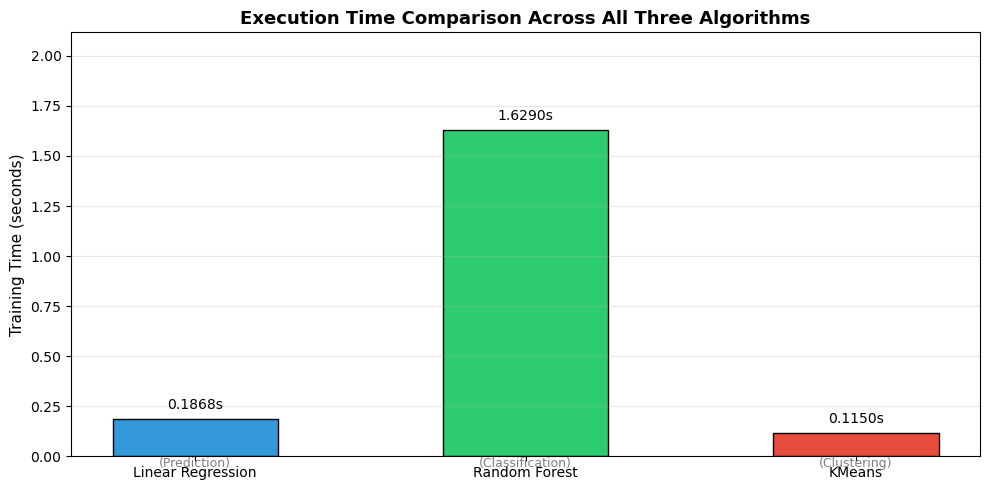

In [ ]:
# =============================================
# CELL 5D: SUMMARY - ALL THREE ALGORITHMS
# =============================================
print("COMPARATIVE SUMMARY OF ALL THREE ALGORITHMS")
print("="*60)
print(f"{'Algorithm':<35} {'Task':<15} {'Metric':<25} {'Time (s)'}")
print("-"*60)
for name, info in results_all.items():
    print(f"{name:<35} {info['type']:<15} {info['metric']:<25} {info['time']:.4f}s")

# Visual summary bar chart
fig, ax = plt.subplots(figsize=(10, 5))
algo_names = [n.split('(')[0].strip() for n in results_all.keys()]
algo_times = [v['time'] for v in results_all.values()]
colors = ['#3498db', '#2ecc71', '#e74c3c']

bars = ax.bar(algo_names, algo_times, color=colors, edgecolor='black', width=0.5)
ax.bar_label(bars, fmt='%.4fs', padding=5, fontsize=10)
ax.set_title("Execution Time Comparison Across All Three Algorithms",
             fontsize=13, fontweight='bold')
ax.set_ylabel("Training Time (seconds)", fontsize=11)
ax.set_ylim(0, max(algo_times) * 1.3)
ax.grid(axis='y', alpha=0.3)

for i, (name, info) in enumerate(results_all.items()):
    ax.text(i, -0.015 * max(algo_times), f"({info['type']})",
            ha='center', fontsize=9, color='gray',
            transform=ax.get_xaxis_transform())

plt.tight_layout()
plt.savefig('figures/algorithm_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

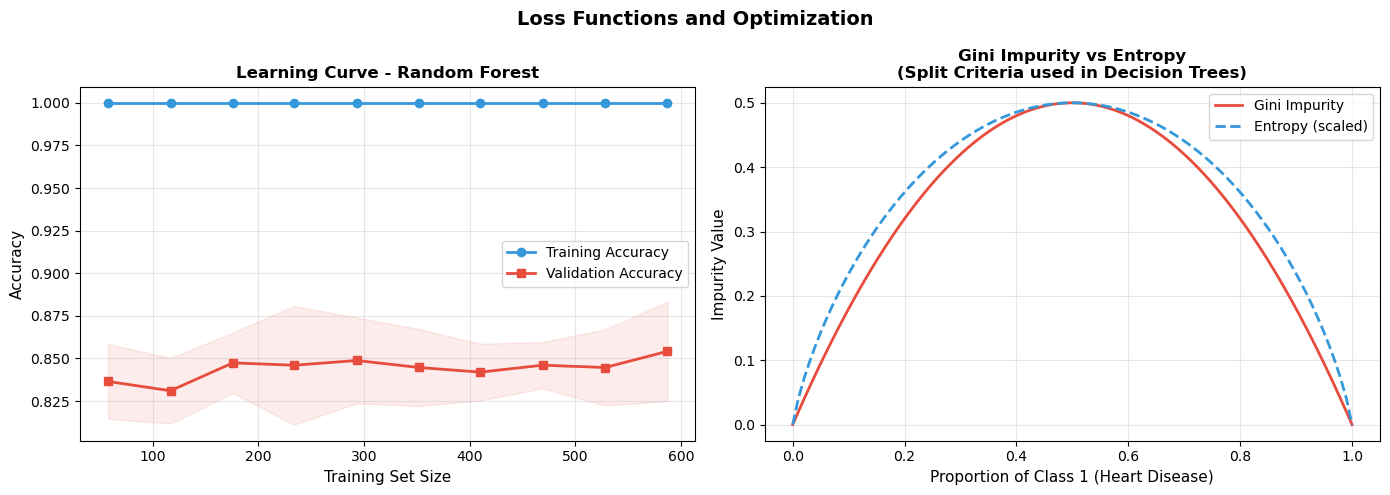


LOSS AND OPTIMIZATION SUMMARY
Linear Regression    -> Mean Squared Error (MSE) Loss
                        Minimized via Ordinary Least Squares (OLS)
                        Beta = (X^T X)^-1 X^T y

Random Forest        -> Gini Impurity at each node split
                        No gradient descent - trees grown greedily
                        Final answer by majority vote across 100 trees

KMeans Clustering    -> Within-Cluster Sum of Squares (WCSS / Inertia)
                        Minimized by iteratively updating cluster centers
                        Center(k) = mean of all points assigned to cluster k



In [ ]:
from sklearn.model_selection import learning_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Loss Functions and Optimization", fontsize=14, fontweight='bold')

# --- Learning curve for Random Forest ---
train_sizes, train_scores, val_scores = learning_curve(
    RandomForestClassifier(n_estimators=100, random_state=42),
    X_train, y_train,
    cv=5,
    scoring='accuracy',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

axes[0].plot(train_sizes, train_scores.mean(axis=1), 'o-',
             label='Training Accuracy', color='#3498db', linewidth=2)
axes[0].plot(train_sizes, val_scores.mean(axis=1), 's-',
             label='Validation Accuracy', color='#e74c3c', linewidth=2)
axes[0].fill_between(train_sizes,
                      train_scores.mean(axis=1) - train_scores.std(axis=1),
                      train_scores.mean(axis=1) + train_scores.std(axis=1),
                      alpha=0.1, color='#3498db')
axes[0].fill_between(train_sizes,
                      val_scores.mean(axis=1) - val_scores.std(axis=1),
                      val_scores.mean(axis=1) + val_scores.std(axis=1),
                      alpha=0.1, color='#e74c3c')
axes[0].set_title("Learning Curve - Random Forest", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Training Set Size", fontsize=11)
axes[0].set_ylabel("Accuracy", fontsize=11)
axes[0].legend(fontsize=10)
axes[0].grid(alpha=0.3)

# --- Gini Impurity illustration ---
p_values = np.linspace(0, 1, 100)
gini = 1 - (p_values**2 + (1 - p_values)**2)
entropy = -np.where(p_values == 0, 0, p_values * np.log2(np.clip(p_values, 1e-10, 1))) \
          -np.where(p_values == 1, 0, (1-p_values) * np.log2(np.clip(1-p_values, 1e-10, 1)))

axes[1].plot(p_values, gini, color='#e74c3c', linewidth=2, label='Gini Impurity')
axes[1].plot(p_values, entropy / 2, color='#3498db', linewidth=2,
             linestyle='--', label='Entropy (scaled)')
axes[1].set_title("Gini Impurity vs Entropy\n(Split Criteria used in Decision Trees)",
                   fontsize=12, fontweight='bold')
axes[1].set_xlabel("Proportion of Class 1 (Heart Disease)", fontsize=11)
axes[1].set_ylabel("Impurity Value", fontsize=11)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('figures/loss_optimization.png', dpi=150, bbox_inches='tight')
plt.show()

print("""
LOSS AND OPTIMIZATION SUMMARY
================================
Linear Regression    -> Mean Squared Error (MSE) Loss
                        Minimized via Ordinary Least Squares (OLS)
                        Beta = (X^T X)^-1 X^T y

Random Forest        -> Gini Impurity at each node split
                        No gradient descent - trees grown greedily
                        Final answer by majority vote across 100 trees
S
KMeans Clustering    -> Within-Cluster Sum of Squares (WCSS / Inertia)
                        Minimized by iteratively updating cluster centers
                        Center(k) = mean of all points assigned to cluster k
""")

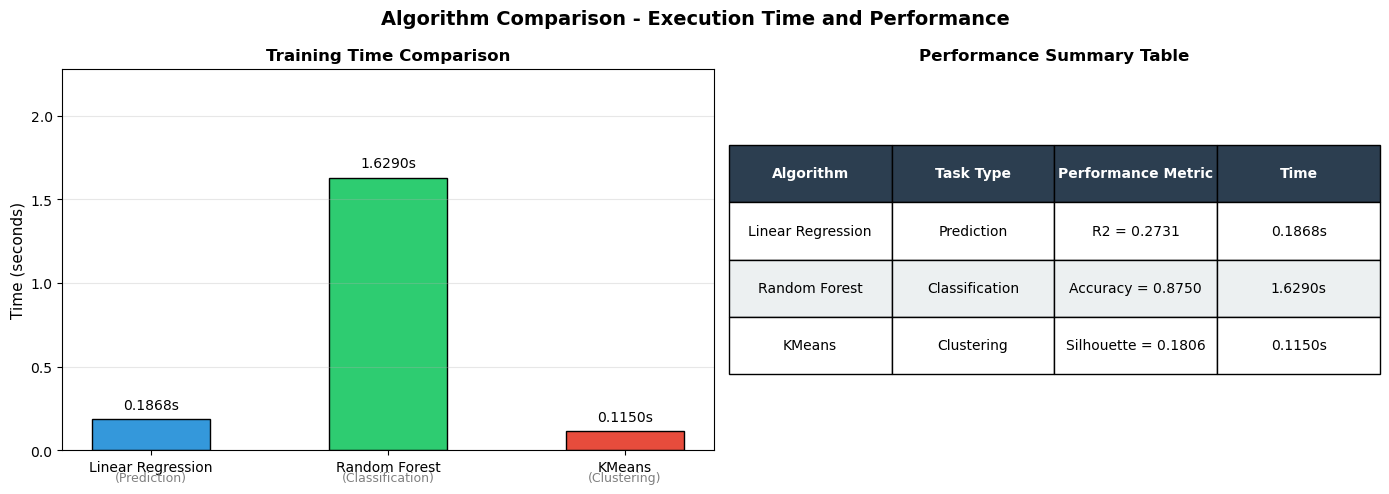

FINAL COMPARISON TABLE
Algorithm                 Task            Metric                    Time
-----------------------------------------------------------------
Linear Regression         Prediction      R2 = 0.2731               0.1868s
Random Forest             Classification  Accuracy = 0.8750         1.6290s
KMeans                    Clustering      Silhouette = 0.1806       0.1150s


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Algorithm Comparison - Execution Time and Performance",
             fontsize=14, fontweight='bold')

algo_names = [n.split('(')[0].strip() for n in results_all.keys()]
algo_times = [v['time'] for v in results_all.values()]
algo_metrics = [v['metric'] for v in results_all.values()]
colors = ['#3498db', '#2ecc71', '#e74c3c']

# Time comparison
bars1 = axes[0].bar(algo_names, algo_times, color=colors,
                     edgecolor='black', width=0.5)
axes[0].bar_label(bars1, fmt='%.4fs', padding=5, fontsize=10)
axes[0].set_title("Training Time Comparison", fontsize=12, fontweight='bold')
axes[0].set_ylabel("Time (seconds)", fontsize=11)
axes[0].set_ylim(0, max(algo_times) * 1.4)
axes[0].grid(axis='y', alpha=0.3)
for i, info in enumerate(results_all.values()):
    axes[0].text(i, -0.08, f"({info['type']})", ha='center',
                  fontsize=9, color='gray',
                  transform=axes[0].get_xaxis_transform())

# Metrics table as text panel
axes[1].axis('off')
table_data = []
for name, info in results_all.items():
    table_data.append([
        name.split('(')[0].strip(),
        info['type'],
        info['metric'],
        f"{info['time']:.4f}s"
    ])

table = axes[1].table(
    cellText=table_data,
    colLabels=['Algorithm', 'Task Type', 'Performance Metric', 'Time'],
    cellLoc='center',
    loc='center',
    bbox=[0, 0.2, 1, 0.6]
)
table.auto_set_font_size(False)
table.set_fontsize(10)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif row % 2 == 0:
        cell.set_facecolor('#ecf0f1')
axes[1].set_title("Performance Summary Table", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/execution_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("FINAL COMPARISON TABLE")
print("="*65)
print(f"{'Algorithm':<25} {'Task':<15} {'Metric':<25} {'Time'}")
print("-"*65)
for name, info in results_all.items():
    print(f"{name.split('(')[0].strip():<25} {info['type']:<15} {info['metric']:<25} {info['time']:.4f}s")

In [19]:
print("PREDICTIONS ON 5 UNSEEN PATIENTS")
print("="*60)

unseen_raw = pd.DataFrame({
    'Age':            [45, 62, 38, 55, 70],
    'Sex':            ['M', 'F', 'M', 'F', 'M'],
    'ChestPainType':  ['ATA', 'ASY', 'NAP', 'TA', 'ASY'],
    'RestingBP':      [130, 160, 110, 140, 170],
    'Cholesterol':    [250, 300, 180, 220, 340],
    'FastingBS':      [0, 1, 0, 0, 1],
    'RestingECG':     ['Normal', 'LVH', 'Normal', 'ST', 'LVH'],
    'MaxHR':          [165, 95, 175, 130, 85],
    'ExerciseAngina': ['N', 'Y', 'N', 'Y', 'Y'],
    'Oldpeak':        [0.5, 3.0, 0.0, 1.5, 2.8],
    'ST_Slope':       ['Up', 'Flat', 'Up', 'Flat', 'Down']
})

# Preprocess unseen data
unseen_clf = unseen_raw.copy()
for col in cat_cols:
    unseen_clf[col] = le.fit_transform(unseen_clf[col])

# For regression prediction (predicting MaxHR)
unseen_reg = unseen_clf.drop('MaxHR', axis=1)
unseen_reg_scaled = scaler_reg.transform(unseen_reg)
unseen_clf_data = unseen_clf.copy()

# Scale for clustering
unseen_scaled = scaler.transform(unseen_clf)

print(f"\n{'Patient':<10} {'Age':<6} {'Sex':<5} {'ChestPain':<12} {'RF Classification':<22} {'Predicted MaxHR':<18} {'Cluster'}")
print("-"*80)

for i in range(len(unseen_raw)):
    rf_p      = rf.predict(unseen_clf_data.iloc[[i]])[0]
    reg_p     = lr_reg.predict(unseen_reg_scaled[[i]])[0]
    cluster_p = kmeans.predict(unseen_scaled[[i]])[0]

    rf_label  = "Heart Disease" if rf_p == 1 else "No Disease"
    print(f"Patient {i+1:<3} {unseen_raw['Age'].iloc[i]:<6} "
          f"{unseen_raw['Sex'].iloc[i]:<5} "
          f"{unseen_raw['ChestPainType'].iloc[i]:<12} "
          f"{rf_label:<22} "
          f"{reg_p:<18.1f} "
          f"Cluster {cluster_p}")

print("\nNote:")
print("  RF Classification -> 0 = No Disease, 1 = Heart Disease")
print("  Predicted MaxHR   -> estimated maximum heart rate in bpm")
print("  Cluster           -> patient group by clinical similarity (0 or 1)")

PREDICTIONS ON 5 UNSEEN PATIENTS

Patient    Age    Sex   ChestPain    RF Classification      Predicted MaxHR    Cluster
--------------------------------------------------------------------------------
Patient 1   45     M     ATA          No Disease             151.4              Cluster 1
Patient 2   62     F     ASY          Heart Disease          134.7              Cluster 0
Patient 3   38     M     NAP          No Disease             159.3              Cluster 1
Patient 4   55     F     TA           Heart Disease          136.5              Cluster 0
Patient 5   70     M     ASY          Heart Disease          113.4              Cluster 0

Note:
  RF Classification -> 0 = No Disease, 1 = Heart Disease
  Predicted MaxHR   -> estimated maximum heart rate in bpm
  Cluster           -> patient group by clinical similarity (0 or 1)
